# Financial Risk Analysis with Python

## For Goldman Sachs

In [2]:
#importing basic importent libraries here.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
#importing received data
df=pd.read_csv(r'F:\Internshala\Internshala projects\InternshalaProjectPython\goldman_sachs.csv')
df

,TransactionID,CustomerID,AccountID,AccountType,TransactionType,Product,Firm,Region,Manager,TransactionDate,TransactionAmount,AccountBalance,RiskScore,CreditRating,TenureMonths
0,33,CUST6549,ACC12334,Credit,Withdrawal,Savings Account,Firm C,Central,Manager 1,21-10-2023,87480.05448,74008.43310,0.729101,319,200
1,177,CUST2942,ACC52650,Credit,Withdrawal,Home Loan,Firm A,East,Manager 3,20-06-2023,20315.74505,22715.83590,0.472424,692,47
2,178,CUST6776,ACC45101,Current,Deposit,Personal Loan,Firm C,South,Manager 3,02-01-2023,10484.57165,42706.09210,0.648784,543,109
3,173,CUST2539,ACC88252,Current,Withdrawal,Mutual Fund,Firm A,Central,Manager 2,25-07-2023,45122.27373,114176.56870,0.734832,430,103
4,67,CUST2626,ACC21878,Savings,Withdrawal,Home Loan,Firm C,Central,Manager 4,25-07-2023,42360.79878,17863.02644,0.289304,468,234
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
795,11,CUST8461,ACC60432,Current,Withdrawal,Credit Card,Firm E,Central,Manager 3,17-02-2023,119878.30500,72041.03969,0.437613,772,217
796,44,CUST1121,ACC41829,Credit,Withdrawal,Personal Loan,Firm C,East,Manager 4,26-10-2023,97933.33752,98317.05068,0.240792,411,78
797,160,CUST3059,ACC28292,Current,Payment,Mutual Fund,Firm E,South,Manager 4,11-05-2023,63072.38174,35088.75351,0.283858,486,215
798,37,CUST1042,ACC28295,Current,Payment,Personal Loan,Firm E,West,Manager 3,26-03-2023,-25289.82472,40794.07619,0.515020,549,238


#### Data Cleaning and Formatting 

In [4]:
numeric_cols=["TransactionID","TransactionAmount","AccountBalance","RiskScore","CreditRating","TenureMonths"]

In [5]:
for col in numeric_cols:
    df[col]=(df[col].astype(str).str.replace(r"[^\d.-]","",regex=True).replace("",pd.NA).astype(float))

In [6]:
df[numeric_cols] = df[numeric_cols].apply(lambda x: x.fillna(x.mean()))

In [7]:
df["TransactionDate"]=pd.to_datetime(df["TransactionDate"],errors="coerce")

C:\Users\PrdiAcerAspireE1-531\AppData\Local\Temp\ipykernel_6536\3242604646.py:1: UserWarning: Parsing dates in %d-%m-%Y format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  df["TransactionDate"]=pd.to_datetime(df["TransactionDate"],errors="coerce")


In [8]:
print(df.dtypes)
df

TransactionID               float64
CustomerID                   object
AccountID                    object
AccountType                  object
TransactionType              object
Product                      object
Firm                         object
Region                       object
Manager                      object
TransactionDate      datetime64[ns]
TransactionAmount           float64
AccountBalance              float64
RiskScore                   float64
CreditRating                float64
TenureMonths                float64
dtype: object


,TransactionID,CustomerID,AccountID,AccountType,TransactionType,Product,Firm,Region,Manager,TransactionDate,TransactionAmount,AccountBalance,RiskScore,CreditRating,TenureMonths
0,33.0,CUST6549,ACC12334,Credit,Withdrawal,Savings Account,Firm C,Central,Manager 1,2023-10-21,87480.05448,74008.43310,0.729101,319.0,200.0
1,177.0,CUST2942,ACC52650,Credit,Withdrawal,Home Loan,Firm A,East,Manager 3,2023-06-20,20315.74505,22715.83590,0.472424,692.0,47.0
2,178.0,CUST6776,ACC45101,Current,Deposit,Personal Loan,Firm C,South,Manager 3,2023-01-02,10484.57165,42706.09210,0.648784,543.0,109.0
3,173.0,CUST2539,ACC88252,Current,Withdrawal,Mutual Fund,Firm A,Central,Manager 2,2023-07-25,45122.27373,114176.56870,0.734832,430.0,103.0
4,67.0,CUST2626,ACC21878,Savings,Withdrawal,Home Loan,Firm C,Central,Manager 4,2023-07-25,42360.79878,17863.02644,0.289304,468.0,234.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
795,11.0,CUST8461,ACC60432,Current,Withdrawal,Credit Card,Firm E,Central,Manager 3,2023-02-17,119878.30500,72041.03969,0.437613,772.0,217.0
796,44.0,CUST1121,ACC41829,Credit,Withdrawal,Personal Loan,Firm C,East,Manager 4,2023-10-26,97933.33752,98317.05068,0.240792,411.0,78.0
797,160.0,CUST3059,ACC28292,Current,Payment,Mutual Fund,Firm E,South,Manager 4,2023-05-11,63072.38174,35088.75351,0.283858,486.0,215.0
798,37.0,CUST1042,ACC28295,Current,Payment,Personal Loan,Firm E,West,Manager 3,2023-03-26,-25289.82472,40794.07619,0.515020,549.0,238.0


In [9]:
df.groupby("TransactionType")["TransactionAmount"].describe()

,count,mean,std,min,25%,50%,75%,max
TransactionType,,,,,,,,
Deposit,199.0,52669.024306,28490.490801,-30721.24789,32648.452635,51877.366170,72537.942195,130149.3799
Payment,200.0,52911.374566,29234.866990,-25289.82472,30993.379640,52610.299170,71318.838470,129983.6051
Transfer,194.0,48224.133479,28035.051303,-27273.43582,29217.071567,46151.192505,65904.342930,118490.4488
Withdrawal,207.0,52375.095491,30302.114143,-24811.42895,33317.044720,50610.277230,73511.848110,130726.9141


In [10]:
df[df["TransactionType"]=="Deposit"]["TransactionAmount"].lt(0).sum()

np.int64(4)

In [11]:
credit_types=["Deposit"]
debit_types=["Withdrawal", "Payment", "Transfer"]

In [12]:
def fix_transaction_sign(row):
    amt=row["TransactionAmount"]
    ttype=row["TransactionType"]

    if pd.isna(amt):
        return amt

    if ttype in credit_types:
        return abs(amt)#deposits must be positive

    if ttype in debit_types:
        return -abs(amt)#debits must be negative

    return amt

In [13]:
df["TransactionAmount"]=df.apply(fix_transaction_sign,axis=1)

In [14]:
df.to_csv(r'F:\Internshala\Internshala projects\InternshalaProjectPython\cleaned_goldman_sachs.csv', index=False)
df

,TransactionID,CustomerID,AccountID,AccountType,TransactionType,Product,Firm,Region,Manager,TransactionDate,TransactionAmount,AccountBalance,RiskScore,CreditRating,TenureMonths
0,33.0,CUST6549,ACC12334,Credit,Withdrawal,Savings Account,Firm C,Central,Manager 1,2023-10-21,-87480.05448,74008.43310,0.729101,319.0,200.0
1,177.0,CUST2942,ACC52650,Credit,Withdrawal,Home Loan,Firm A,East,Manager 3,2023-06-20,-20315.74505,22715.83590,0.472424,692.0,47.0
2,178.0,CUST6776,ACC45101,Current,Deposit,Personal Loan,Firm C,South,Manager 3,2023-01-02,10484.57165,42706.09210,0.648784,543.0,109.0
3,173.0,CUST2539,ACC88252,Current,Withdrawal,Mutual Fund,Firm A,Central,Manager 2,2023-07-25,-45122.27373,114176.56870,0.734832,430.0,103.0
4,67.0,CUST2626,ACC21878,Savings,Withdrawal,Home Loan,Firm C,Central,Manager 4,2023-07-25,-42360.79878,17863.02644,0.289304,468.0,234.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
795,11.0,CUST8461,ACC60432,Current,Withdrawal,Credit Card,Firm E,Central,Manager 3,2023-02-17,-119878.30500,72041.03969,0.437613,772.0,217.0
796,44.0,CUST1121,ACC41829,Credit,Withdrawal,Personal Loan,Firm C,East,Manager 4,2023-10-26,-97933.33752,98317.05068,0.240792,411.0,78.0
797,160.0,CUST3059,ACC28292,Current,Payment,Mutual Fund,Firm E,South,Manager 4,2023-05-11,-63072.38174,35088.75351,0.283858,486.0,215.0
798,37.0,CUST1042,ACC28295,Current,Payment,Personal Loan,Firm E,West,Manager 3,2023-03-26,-25289.82472,40794.07619,0.515020,549.0,238.0


#### Descriptive Transactional Analysis

##### ● Calculating monthly and yearly summaries of total credits, debits, and net transaction volume.


In [15]:
#creating credit/debit indicator
credit_types = ["Deposit"]
debit_types = ["Withdrawal", "Payment", "Transfer"]

df["CreditAmount"]=df.apply(lambda x: x["TransactionAmount"] if x["TransactionType"] in credit_types else 0,axis=1)

df["DebitAmount"]=df.apply(lambda x: x["TransactionAmount"] if x["TransactionType"] in debit_types else 0,axis=1)

#creating month and year columns
df["Year"]=df["TransactionDate"].dt.year
df["Month"]=df["TransactionDate"].dt.to_period("M")

#Calculating monthly of total credits, debits, and net transaction volume
monthly_summary=(df.groupby("Month").agg(TotalCredits=("CreditAmount", "sum"),TotalDebits=("DebitAmount", "sum"))
      .reset_index())
monthly_summary["NetTransactionVolume"] = (monthly_summary["TotalCredits"] - monthly_summary["TotalDebits"])

#Calculating yearly of total credits, debits, and net transaction volume
yearly_summary=(df.groupby("Year").agg(TotalCredits=("CreditAmount", "sum"),TotalDebits=("DebitAmount", "sum"))
      .reset_index())
yearly_summary["NetTransactionVolume"]=(yearly_summary["TotalCredits"]-yearly_summary["TotalDebits"])

#printing results
print("Monthly Summary")
print(monthly_summary)

print("\nYearly Summary")
print(yearly_summary)

Monthly Summary
      Month   TotalCredits   TotalDebits  NetTransactionVolume
0   2023-01  762099.557830 -2.380984e+06          3.143084e+06
1   2023-02  648261.004850 -1.436502e+06          2.084763e+06
2   2023-03  604002.422140 -2.098983e+06          2.702986e+06
3   2023-04  439321.687687 -1.338294e+06          1.777616e+06
4   2023-05  425589.871840 -2.203715e+06          2.629305e+06
5   2023-06  469388.806400 -8.996432e+05          1.369032e+06
6   2023-07  648027.880060 -9.513957e+05          1.599424e+06
7   2023-08  544970.364060 -2.011232e+06          2.556202e+06
8   2023-09  712838.795016 -1.612681e+06          2.325520e+06
9   2023-10  700356.904091 -2.466516e+06          3.166873e+06
10  2023-11  743507.571671 -2.281579e+06          3.025087e+06
11  2023-12  587483.874090 -1.718421e+06          2.305904e+06
12  2024-01  468686.365530 -1.782994e+06          2.251680e+06
13  2024-02  675070.922370 -2.448582e+06          3.123653e+06
14  2024-03  481619.617082 -1.980047e+0

##### ● Plotting trends in total credits vs. debits over time.

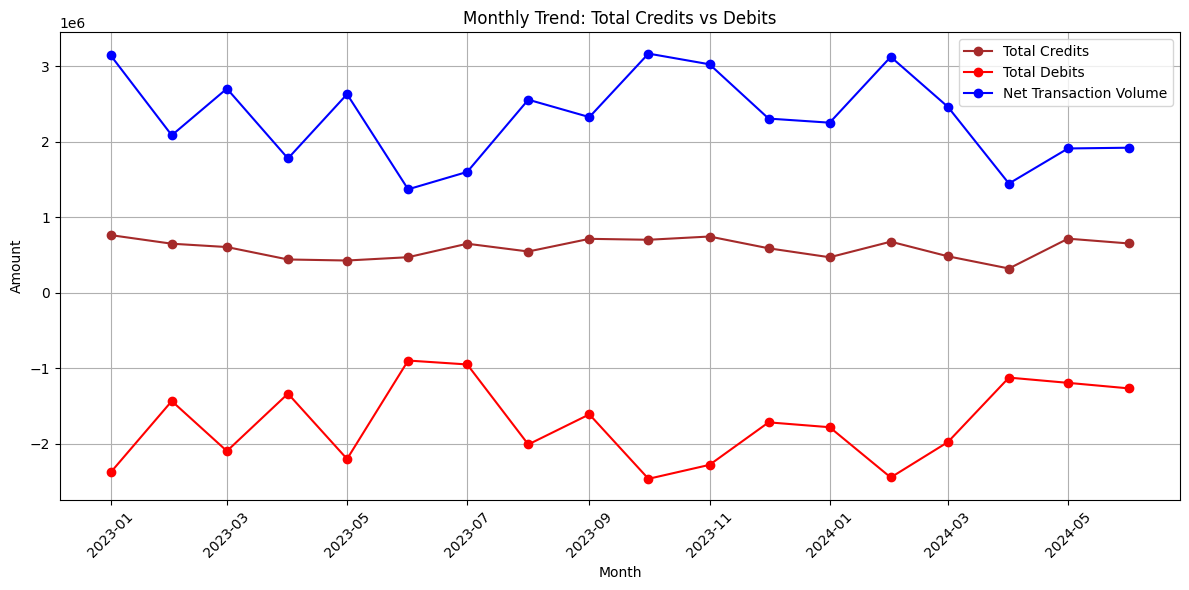

In [16]:
if not pd.api.types.is_datetime64_any_dtype(monthly_summary['Month']):
    # If it's Period, convert to timestamp
    if isinstance(monthly_summary['Month'].iloc[0], pd.Period):
        monthly_summary['Month']=monthly_summary['Month'].dt.to_timestamp()
    else:
        # Otherwise, try parsing as datetime
        monthly_summary['Month']=pd.to_datetime(monthly_summary['Month'], errors='coerce')

# Drop rows with invalid dates
monthly_summary=monthly_summary.dropna(subset=['Month'])

# Plot monthly trends
plt.figure(figsize=(12,6))
plt.plot(monthly_summary['Month'],monthly_summary['TotalCredits'],marker='o',label='Total Credits',color='brown')
plt.plot(monthly_summary['Month'],monthly_summary['TotalDebits'],marker='o',label='Total Debits',color='red')
plt.plot(monthly_summary['Month'],monthly_summary['NetTransactionVolume'],marker='o'
         ,label='Net Transaction Volume', color='blue')

plt.title('Monthly Trend: Total Credits vs Debits')
plt.xlabel('Month')
plt.ylabel('Amount')
plt.xticks(rotation=45)
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

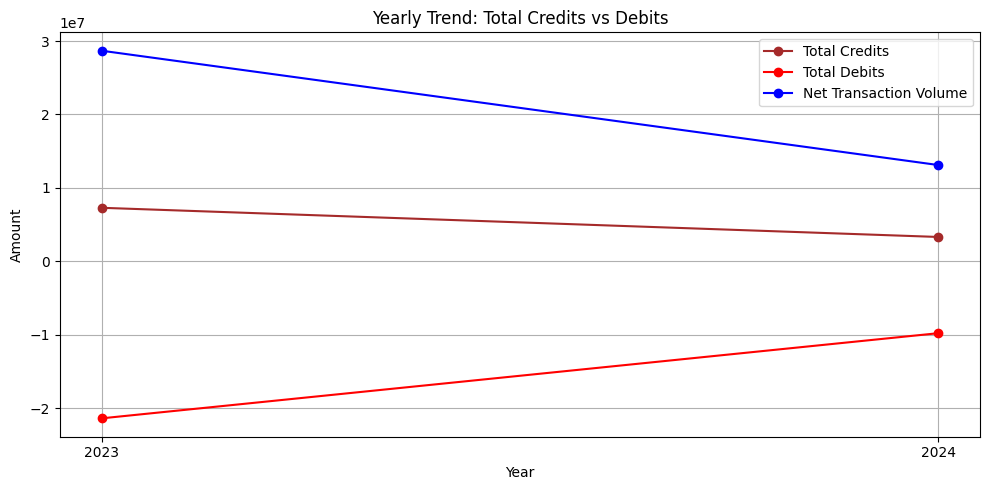

In [17]:
yearly_summary['Year'] = yearly_summary['Year'].astype(int)

# Sort by year (important for line plot)
yearly_summary = yearly_summary.sort_values('Year')
plt.figure(figsize=(10,5))

plt.plot(yearly_summary['Year'],yearly_summary['TotalCredits'],marker='o',label='Total Credits',color='brown')
plt.plot(yearly_summary['Year'],yearly_summary['TotalDebits'],marker='o',label='Total Debits',color='red')
plt.plot(yearly_summary['Year'],yearly_summary['NetTransactionVolume'],marker='o',color='blue',
    label='Net Transaction Volume')

plt.title('Yearly Trend: Total Credits vs Debits')
plt.xlabel('Year')
plt.ylabel('Amount')
plt.xticks(yearly_summary['Year'])
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

##### ● Identifying top and bottom performing accounts based on net inflow

In [18]:
account_summary=df.groupby("AccountID").agg(TotalCredits=("CreditAmount", "sum"),
                        TotalDebits=("DebitAmount", "sum")).reset_index()

account_summary["NetInflow"] = account_summary["TotalCredits"]-account_summary["TotalDebits"]

top_accounts=account_summary.sort_values(by="NetInflow", ascending=False).head(10)
bottom_accounts=account_summary.sort_values(by="NetInflow", ascending=True).head(10)

# Step 5: Print results
print("Top 10 Accounts by Net Inflow")
print(top_accounts)

print("\nBottom 10 Accounts by Net Inflow")
print(bottom_accounts)

Top 10 Accounts by Net Inflow
    AccountID   TotalCredits    TotalDebits      NetInflow
88   ACC46655  222319.965033 -522082.805742  744402.770775
60   ACC33287  390354.426410 -201236.669480  591591.095890
13   ACC16241  103643.144550 -435968.998300  539612.142850
107  ACC53466   18181.673810 -476775.484990  494957.158800
49   ACC29396   39888.001430 -442832.014120  482720.015550
164  ACC83269  242156.810620 -226577.784770  468734.595390
114  ACC57700  108837.513680 -356210.412734  465047.926414
118  ACC60432   39623.167300 -423334.682580  462957.849880
48   ACC29356   27344.624350 -408228.871838  435573.496188
153  ACC78178   40976.425810 -392683.438450  433659.864260

Bottom 10 Accounts by Net Inflow
    AccountID  TotalCredits   TotalDebits     NetInflow
82   ACC43771      0.000000 -14033.502560  14033.502560
39   ACC26956      0.000000 -15603.452120  15603.452120
23   ACC21429      0.000000 -20442.761880  20442.761880
89   ACC46953      0.000000 -24811.428950  24811.428950
152  AC

##### ● Identifying and flaging accounts as dormant or inactive if there is a gap of two months or more between consecutive transactions.

In [19]:
df=df.sort_values(by=['AccountID', 'TransactionDate'])

#Calculate difference in months between consecutive transactions per account
df['PrevTransactionDate']=df.groupby('AccountID')['TransactionDate'].shift(1)
df['MonthGap']=((df['TransactionDate'].dt.year - df['PrevTransactionDate'].dt.year) * 12 +
                  (df['TransactionDate'].dt.month - df['PrevTransactionDate'].dt.month))

#Flag dormant/inactive accounts: gap >= 2 months
df['DormantFlag']=df['MonthGap'] >= 2

#Get a list of accounts that are currently dormant (last transaction > 2 months ago)
latest_transaction=df.groupby('AccountID')['TransactionDate'].max().reset_index()
latest_transaction['MonthsSinceLastTransaction']=((pd.Timestamp.today().year-latest_transaction['TransactionDate']
        .dt.year)*12+(pd.Timestamp.today().month-latest_transaction['TransactionDate'].dt.month))
latest_transaction['DormantAccount'] = latest_transaction['MonthsSinceLastTransaction'] >= 2

# Display results
print("Dormant Transactions:")
print(df[df['DormantFlag']==True][['AccountID','TransactionDate','PrevTransactionDate','MonthGap']])

print("\nDormant Accounts (as of today) : ")
print(latest_transaction[latest_transaction['DormantAccount']==True])

Dormant Transactions:
    AccountID TransactionDate PrevTransactionDate  MonthGap
87   ACC10117      2023-06-18          2023-02-21       4.0
742  ACC10117      2024-03-14          2023-06-18       9.0
294  ACC10996      2023-10-19          2023-05-08       5.0
574  ACC10996      2024-01-29          2023-10-21       3.0
551  ACC11062      2024-02-08          2023-11-08       3.0
..        ...             ...                 ...       ...
221  ACC99409      2023-09-30          2023-05-04       4.0
542  ACC99409      2024-03-22          2023-10-04       5.0
504  ACC99549      2023-08-04          2023-04-14       4.0
706  ACC99549      2023-10-26          2023-08-04       2.0
510  ACC99549      2024-02-18          2023-10-26       4.0

[385 rows x 4 columns]

Dormant Accounts (as of today) : 
    AccountID TransactionDate  MonthsSinceLastTransaction  DormantAccount
0    ACC10117      2024-03-14                          22            True
1    ACC10996      2024-02-09                      

#### Customer Profile Building

##### ● Group accounts by activity levels: High, Medium, Low based on transaction frequency on your analysis and rubrics. Do not forget to mention the rubric in the headings.


In [20]:
#getting maximum and minimum trasactions by customers
transaction_counts=df.groupby('CustomerID').agg(NumTransactions=('TransactionID', 'count')).reset_index()

max_transactions=transaction_counts['NumTransactions'].max()
min_transactions=transaction_counts['NumTransactions'].min()
print(max_transactions)
print(min_transactions)

11
1


In [21]:
account_transactions = df.groupby('AccountID').agg(TransactionCount=('TransactionID', 'count')).reset_index()

#Defining function to classify activity levels
#'High' if count is between 7-11, 'Medium' if count is between 4-6, 'Low' if count is below or equal to 3.
def classify_activity(count):
    if 7<=count<=11:
        return 'High'
    elif 4<=count<= 6:
        return 'Medium'
    elif 1<=count<=3:
        return 'Low'
    else:
        return 'Inactive'  # Optional: for accounts with 0 transactions

#Applying the function
account_transactions['ActivityLevel'] = account_transactions['TransactionCount'].apply(classify_activity)

#Merging back with original data if needed
df = df.merge(account_transactions[['AccountID', 'ActivityLevel']], on='AccountID', how='left')

#Viewing summary
activity_summary=account_transactions['ActivityLevel'].value_counts()
print("Activity Level Summary:")
print(activity_summary)

#Displaying accounts with their activity level
print("\nAccounts with Activity Levels:")
print(account_transactions)

Activity Level Summary:
ActivityLevel
Medium      92
Low         79
High        22
Inactive     1
Name: count, dtype: int64

Accounts with Activity Levels:
    AccountID  TransactionCount ActivityLevel
0    ACC10117                 4        Medium
1    ACC10996                 5        Medium
2    ACC11062                 2           Low
3    ACC11188                 5        Medium
4    ACC11285                 3           Low
..        ...               ...           ...
189  ACC97225                 3           Low
190  ACC97411                 2           Low
191  ACC99117                 3           Low
192  ACC99409                 4        Medium
193  ACC99549                 4        Medium

[194 rows x 3 columns]


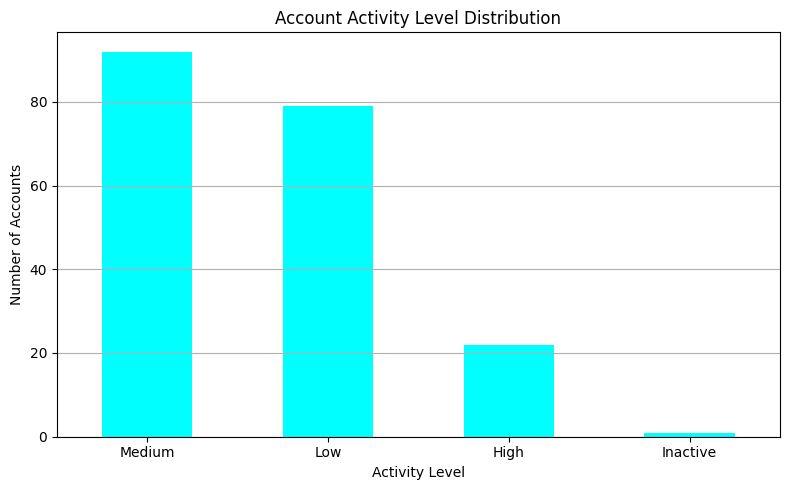

In [22]:
plt.figure(figsize=(8,5))
activity_summary.plot(kind='bar',color='cyan')

plt.title('Account Activity Level Distribution')
plt.xlabel('Activity Level')
plt.ylabel('Number of Accounts')
plt.xticks(rotation=0)
plt.grid(axis='y')
plt.tight_layout()
plt.show()

##### ● Segmenting customers by average balance and transaction volume

In [43]:
#getting customers average balence and transaction volume
customer_summary=df.groupby('CustomerID').agg(AvgBalance=('AccountBalance','mean'),
    TransactionVolume=('TransactionAmount','sum'),NumTransactions=('TransactionID','count')).reset_index()

#segmenting customers as 'High Value' if 'AvgBalance'>80000, 'Medium Value' if 'AvgBalance'<=80000 and 
# 'AvgBalance'>=65000,else as 'Low Value'
def segment_customer(row):
    if row['AvgBalance']>80000:
        return 'High Value'
    elif 65000>=row['AvgBalance']<=80000:
        return 'Medium Value'
    else:
        return 'Low Value'

customer_summary['Segment']=customer_summary.apply(segment_customer, axis=1)
# Count of customers per segment
segment_counts=customer_summary['Segment'].value_counts()
print("Customer Segments:")
print(segment_counts)

#Viewing results
print("\nSample Customer Segmentation:")
print(customer_summary)

Customer Segments:
Segment
Low Value       74
High Value      59
Medium Value    55
Name: count, dtype: int64

Sample Customer Segmentation:
    CustomerID    AvgBalance  TransactionVolume  NumTransactions       Segment
0     CUST1042  80435.167530     -284936.864820                8    High Value
1     CUST1114  60127.893845     -268029.670739                8  Medium Value
2     CUST1121  83213.472732     -398205.117510                4    High Value
3     CUST1189  63648.890237     -117339.418890                3  Medium Value
4     CUST1223  88186.197605       29853.686720                2    High Value
..         ...           ...                ...              ...           ...
183   CUST9683  68647.634673     -272292.278850                7     Low Value
184   CUST9731  81032.513290      -34485.367877                6    High Value
185   CUST9754  86529.583115     -104550.322380                8    High Value
186   CUST9843  70615.410052       21078.047810                4     

In [24]:
account_summary=df.groupby('AccountID').agg(TotalCredits=('CreditAmount','sum'),TotalDebits=('DebitAmount','sum'),
    NumTransactions=('TransactionID','count'),AvgBalance=('AccountBalance','mean')).reset_index()

# Calculate net inflow
account_summary['NetInflow'] = account_summary['TotalCredits']-account_summary['TotalDebits']

#High net inflow
high_net_inflow=account_summary[account_summary['NetInflow']>account_summary['NetInflow'].quantile(0.75)]

#High-frequency, low-balance accounts
high_freq_low_balance=account_summary[
    (account_summary['NumTransactions']>=account_summary['NumTransactions'].quantile(0.75)) & 
    (account_summary['AvgBalance']<=account_summary['AvgBalance'].quantile(0.25))]

#Accounts with negative or near-zero balances
negative_or_zero_balance=account_summary[account_summary['AvgBalance'] <= 0]

print("High Net Inflow Accounts : ")
print(high_net_inflow)

High Net Inflow Accounts : 
    AccountID   TotalCredits    TotalDebits  NumTransactions    AvgBalance  \
7    ACC12334  149116.797610 -161110.492080                6  78082.517883   
8    ACC13357   51877.366170 -380650.442090                6  69179.806513   
13   ACC16241  103643.144550 -435968.998300               10  73521.710375   
24   ACC21719   30721.247890 -286563.610770                6  84616.472088   
29   ACC23736   94791.159750 -215006.483120                7  60801.533102   
42   ACC28292   48346.512430 -328128.549718               10  51228.003570   
43   ACC28295   61445.424570 -250348.193300                6  79114.176982   
48   ACC29356   27344.624350 -408228.871838                9  91799.550571   
49   ACC29396   39888.001430 -442832.014120                8  80302.140096   
55   ACC31539   25819.700530 -376944.670070                6  45185.938342   
56   ACC31902  204456.942670 -126739.664910                5  75207.818822   
57   ACC32212  120610.739770 -263434

In [25]:
print("\nHigh-Frequency, Low-Balance Accounts : ")
print(high_freq_low_balance)


High-Frequency, Low-Balance Accounts : 
    AccountID  TotalCredits    TotalDebits  NumTransactions    AvgBalance  \
1    ACC10996   62580.86356 -188158.687390                5  43568.008084   
31   ACC24070   57864.13275 -200459.503500                5  55694.967801   
40   ACC26973   57426.71190 -231599.605364                5  58738.210687   
42   ACC28292   48346.51243 -328128.549718               10  51228.003570   
55   ACC31539   25819.70053 -376944.670070                6  45185.938342   
60   ACC33287  390354.42641 -201236.669480                8  59331.981186   
98   ACC49774  138953.60860 -120197.260980                7  54898.786583   
117  ACC58667   32337.37579 -268691.831640                5  57596.212717   
120  ACC61926  101339.09064 -251892.112680                6  53209.096892   
136  ACC71388   35471.89391 -279506.118460                5  52366.145184   
141  ACC74631  142198.24014 -156645.245550                6  50478.579943   
155  ACC78589   81674.92567 -161649

In [26]:
print("\nAccounts with Negative or Near-Zero Balances : ")
print(negative_or_zero_balance)


Accounts with Negative or Near-Zero Balances : 
   AccountID  TotalCredits  TotalDebits  NumTransactions   AvgBalance  \
20  ACC19178   64100.78213          0.0                1 -1541.176812   

      NetInflow  
20  64100.78213  


#### Financial Risk Identification


##### ● Track accounts with frequent large withdrawals or overdrafts.

In [27]:
# Define threshold for large withdrawal (here>50,000)
large_withdrawal_threshold=50000

# Flag large withdrawals
df['LargeWithdrawal']=((df['TransactionType'].isin(['Withdrawal','Payment','Transfer'])) & 
                         (df['TransactionAmount'] >= large_withdrawal_threshold))

# Flag overdrafts (balance < 0)
df['Overdraft']=df['AccountBalance'] < 0

account_risk_summary=df.groupby('AccountID').agg(NumLargeWithdrawals=('LargeWithdrawal','sum'),
    NumOverdrafts=('Overdraft','sum'),TotalTransactions=('TransactionID','count')).reset_index()


#definining “frequent” as ≥ 3 events
frequent_large_withdrawals=account_risk_summary[account_risk_summary['NumLargeWithdrawals']>=3]
frequent_overdrafts=account_risk_summary[account_risk_summary['NumOverdrafts']>=3]

print("Accounts with Frequent Large Withdrawals : ")
print(frequent_large_withdrawals)

print("\nAccounts with Frequent Overdrafts : ")
print(frequent_overdrafts)

Accounts with Frequent Large Withdrawals : 
Empty DataFrame
Columns: [AccountID, NumLargeWithdrawals, NumOverdrafts, TotalTransactions]
Index: []

Accounts with Frequent Overdrafts : 
Empty DataFrame
Columns: [AccountID, NumLargeWithdrawals, NumOverdrafts, TotalTransactions]
Index: []


##### ● Calculate balance volatility using standard deviation or coefficient of variation.

In [28]:
# Group by AccountID
balance_volatility=df.groupby('AccountID').agg(AvgBalance=('AccountBalance', 'mean'),
         BalanceSD=('AccountBalance', 'std')).reset_index()

# Calculate coefficient of variation (CV)
balance_volatility['BalanceCV']=balance_volatility['BalanceSD'] / balance_volatility['AvgBalance']

# Optional: replace NaN CV with 0 (accounts with single transaction)
balance_volatility['BalanceCV']=balance_volatility['BalanceCV'].fillna(0)

# Top 10 accounts with highest balance volatility (CV)
top_volatility=balance_volatility.sort_values(by='BalanceCV', ascending=False).head(10)
print("Top 10 Accounts by Balance Volatility:")
print(top_volatility)

# Example summary statistics
print("\nBalance Volatility Summary:")
print(balance_volatility['BalanceCV'].describe())

Top 10 Accounts by Balance Volatility:
    AccountID    AvgBalance     BalanceSD  BalanceCV
50   ACC29477  34047.753303  53336.382019   1.566517
133  ACC70314  32004.163562  49242.715939   1.538635
87   ACC45968  44919.543814  50474.312658   1.123660
25   ACC21878  67726.446770  70517.525297   1.041211
117  ACC58667  57596.212717  58637.344639   1.018076
163  ACC83005  25651.786935  24240.202325   0.944971
110  ACC55331  46130.682363  41560.544827   0.900931
98   ACC49774  54898.786583  45904.129015   0.836159
29   ACC23736  60801.533102  48785.760924   0.802377
60   ACC33287  59331.981186  47466.413833   0.800014

Balance Volatility Summary:
count    194.000000
mean       0.411982
std        0.262783
min        0.000000
25%        0.237033
50%        0.393418
75%        0.543067
max        1.566517
Name: BalanceCV, dtype: float64


##### ● Using IQR to detect anomalies.

In [29]:
def detect_outliers_iqr(series):
    Q1=series.quantile(0.25)
    Q3=series.quantile(0.75)
    IQR=Q3-Q1
    lower_bound=Q1-1.5*IQR
    upper_bound=Q3+1.5*IQR
    return (series<lower_bound) | (series>upper_bound)

for col in numeric_cols:
    df[col+'_Outlier']=detect_outliers_iqr(df[col])

#view anomalies
outliers = df[(df['TransactionAmount_Outlier']) | (df['AccountBalance_Outlier']) |(df['RiskScore_Outlier'])]

print("Detected Outliers:")
print(outliers.head(20))

for col in numeric_cols:
    print(f"{col}Outliers:{df[col+'_Outlier'].sum()}")

Detected Outliers:
     TransactionID CustomerID AccountID AccountType TransactionType  \
19            52.0   CUST7730  ACC11837     Savings        Transfer   
44            68.0   CUST8772  ACC15359        Loan      Withdrawal   
45            91.0   CUST2578  ACC15359     Current         Deposit   
76           128.0   CUST5320  ACC18140        Loan         Deposit   
104          134.0   CUST3449  ACC21878     Savings         Deposit   
151          109.0   CUST9066  ACC26940        Loan         Deposit   
211           31.0   CUST5920  ACC29477        Loan         Deposit   
216           76.0   CUST8028  ACC30787     Savings         Deposit   
227           69.0   CUST4669  ACC31902     Savings         Deposit   
236            4.0   CUST8529  ACC32212     Current         Deposit   
248           90.0   CUST4461  ACC33287      Credit         Deposit   
251          195.0   CUST5121  ACC33287        Loan         Deposit   
266          103.0   CUST3041  ACC34821     Savings       

C:\Users\PrdiAcerAspireE1-531\AppData\Local\Temp\ipykernel_6536\3741539215.py:2: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot([df[col] for col in numeric_cols],labels=numeric_cols,showfliers=True)


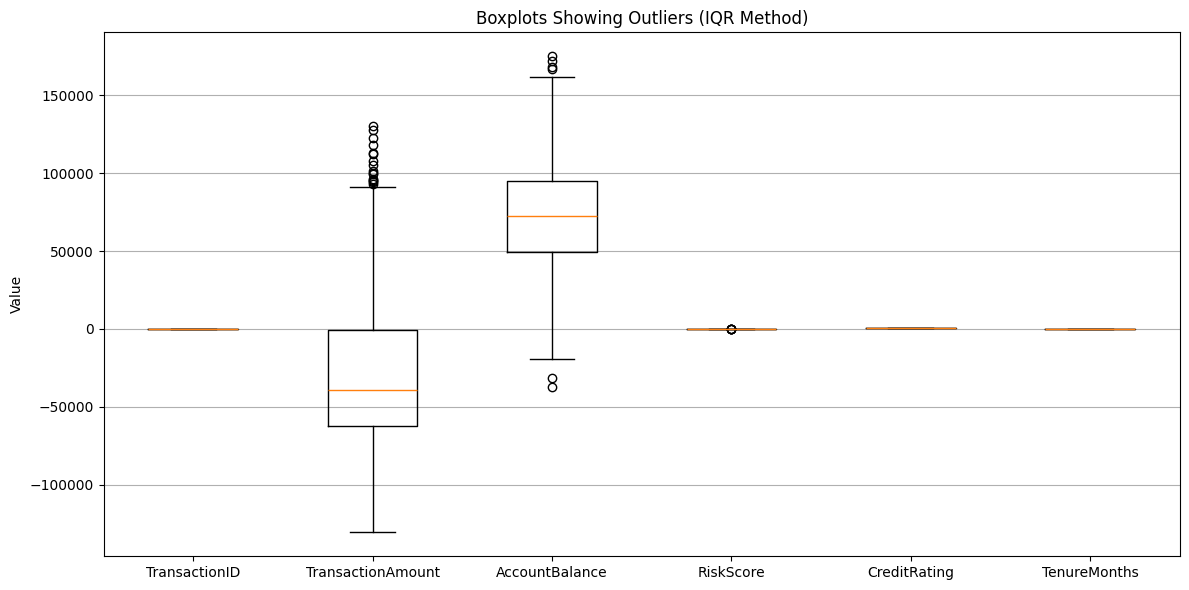

In [30]:
plt.figure(figsize=(12,6))
plt.boxplot([df[col] for col in numeric_cols],labels=numeric_cols,showfliers=True)

plt.title('Boxplots Showing Outliers (IQR Method)')
plt.ylabel('Value')
plt.grid(axis='y')
plt.tight_layout()
plt.show()

##### ● Highlighting customers with irregular or suspicious transaction behavior

In [31]:
#1.Ensuring correct data types
df['TransactionAmount']=pd.to_numeric(df['TransactionAmount'],errors='coerce')
df['AccountBalance']=pd.to_numeric(df['AccountBalance'],errors='coerce')
df['TransactionDate']=pd.to_datetime(df['TransactionDate'])

#2.Large transaction detection (customer-level z-score)
df['CustMeanAmt']=df.groupby('CustomerID')['TransactionAmount'].transform('mean')
df['CustStdAmt']=df.groupby('CustomerID')['TransactionAmount'].transform('std')

df['LargeTxnFlag']=(df['TransactionAmount'] > (df['CustMeanAmt'] + 3 * df['CustStdAmt']))


#3.Overdraft detection
df['OverdraftFlag']=df['AccountBalance'] < 0

#4.High transaction frequency (monthly)
df['YearMonth']=df['TransactionDate'].dt.to_period('M').astype(str)

df['MonthlyTxnCount']=(df.groupby(['CustomerID', 'YearMonth'])['TransactionID'].transform('count'))

high_freq_threshold=df['MonthlyTxnCount'].quantile(0.95)
df['HighFreqFlag']=df['MonthlyTxnCount'] >= high_freq_threshold

#5.Balance volatility (Coefficient of Variation)
df['CustAvgBal']=df.groupby('CustomerID')['AccountBalance'].transform('mean')
df['CustStdBal']=df.groupby('CustomerID')['AccountBalance'].transform('std')

df['BalanceCV']=df['CustStdBal']/df['CustAvgBal']
df['HighVolatilityFlag']=df['BalanceCV'] > df['BalanceCV'].quantile(0.90)


#6.Customer-level suspicious summary
suspicious_customers = (
    df.groupby('CustomerID').agg(
          TotalTransactions=('TransactionID','count'),
          LargeTxns=('LargeTxnFlag','sum'),
          Overdrafts=('OverdraftFlag','sum'),
          HighFreqMonths=('HighFreqFlag','sum'),
          AvgBalance=('AccountBalance','mean'),
          BalanceVolatility=('BalanceCV','mean')).reset_index())


#7.Final suspicious flag
suspicious_customers['Suspicious']=((suspicious_customers['LargeTxns']>0) |
    (suspicious_customers['Overdrafts']>0) |
    (suspicious_customers['HighFreqMonths']>0) |
    (suspicious_customers['BalanceVolatility']>suspicious_customers['BalanceVolatility'].quantile(0.90)))

#8.Output suspicious customers
flagged_customers=suspicious_customers[suspicious_customers['Suspicious']].sort_values(
    ['LargeTxns','Overdrafts','HighFreqMonths'],ascending=False)

print("Suspicious Customers : ")
print(flagged_customers)

Suspicious Customers : 
    CustomerID  TotalTransactions  LargeTxns  Overdrafts  HighFreqMonths  \
1     CUST1114                  8          0           1               4   
52    CUST3041                  6          0           1               4   
31    CUST2412                  5          0           1               2   
41    CUST2694                  5          0           1               2   
92    CUST5121                  4          0           1               2   
..         ...                ...        ...         ...             ...   
66    CUST3762                  2          0           0               0   
122   CUST6391                  3          0           0               0   
133   CUST7028                  2          0           0               0   
134   CUST7098                  3          0           0               0   
143   CUST7493                  2          0           0               0   

       AvgBalance  BalanceVolatility  Suspicious  
1    60127.8

##### ● Testing whether high-volume transaction accounts have statistically higher average balances than low-volume accounts

In [32]:
from scipy import stats
#testing whether high-volume transaction accounts have statistically higher average balances than low-volume accounts

#Ensure numeric
df['AccountBalance']=pd.to_numeric(df['AccountBalance'], errors='coerce')

#Count transactions per account
txn_counts=df.groupby('AccountID').size().reset_index(name='TxnCount')

#Determine thresholds
high_threshold=txn_counts['TxnCount'].quantile(0.75)
low_threshold=txn_counts['TxnCount'].quantile(0.25)

#Classify volume
txn_counts['VolumeGroup']='Medium'
txn_counts.loc[txn_counts['TxnCount']>=high_threshold, 'VolumeGroup'] = 'High'
txn_counts.loc[txn_counts['TxnCount']<=low_threshold, 'VolumeGroup'] = 'Low'

avg_balance=df.groupby('AccountID')['AccountBalance'].mean().reset_index(name='AvgBalance')

#Merge with volume classification
account_data=txn_counts.merge(avg_balance, on='AccountID', how='inner')

high_volume_balances=account_data.loc[account_data['VolumeGroup'] == 'High', 'AvgBalance'].dropna()

low_volume_balances=account_data.loc[account_data['VolumeGroup'] == 'Low', 'AvgBalance'].dropna()

t_stat, p_value=stats.ttest_ind(high_volume_balances,low_volume_balances,equal_var=False,alternative='greater')

print("T-statistic : ", t_stat)
print("P-value : ", p_value)

T-statistic :  0.33907510857958795
P-value :  0.3675629413333966


In [33]:
alpha=0.05

if p_value<alpha:
    print("Reject H0: High-volume accounts have statistically higher average balances.")
else:
    print("Fail to reject H0: No statistical evidence of higher balances.")

Fail to reject H0: No statistical evidence of higher balances.


##### ● Conducting hypothesis testing based on segmentation.

In [34]:
#Chi-square test

#Create transaction frequency category
txn_freq=df.groupby('CustomerID').size().reset_index(name='TxnCount')

txn_freq['FreqSegment']=pd.cut(txn_freq['TxnCount'],bins=[0,3,6,100],labels=['Low','Medium','High'])

credit_map=df[['CustomerID','CreditRating']].drop_duplicates()
chi_df=txn_freq.merge(credit_map, on='CustomerID')

#Contingency table
cont_table=pd.crosstab(chi_df['FreqSegment'], chi_df['CreditRating'])

chi2,p_val,dof,expected=stats.chi2_contingency(cont_table)

print("Chi-square : ",chi2)
print("P-value : ",p_val)

Chi-square :  804.6157993996701
P-value :  0.696477140423722


In [35]:
if p_val < 0.05:
    print("Transaction frequency depends on credit rating.")
else:
    print("Transaction frequency is independent of credit rating.")

Transaction frequency is independent of credit rating.


#Video link is
#https://drive.google.com/file/d/1FXjvL_fiJgnyYiuT7U4nBB8HfOl2ik4A/view?usp=sharing